# Interactive layer stacks

A stack of thin layers reflects and transmits light by interference: each
interface sends back part of the light, and the partial waves from all
interfaces add up with the phases they picked up in the layers. A single
quarter wave layer cancels the reflection of glass; a few dozen alternating
layers make a mirror that reflects more than 99.9 %; with absorbing layers,
part of the light stays in the stack.

This notebook turns `pyoptics.thin_films` into a small interactive stack
designer: choose the number of layers, their refractive indices and thicknesses,
the polarization, the wavelength range and the angle of incidence, and look at
the reflectance $R$, transmittance $T$ and absorptance $A = 1 - R - T$ as a
function of wavelength and of the angle of incidence. The second part adds
material dispersion with an **Abbe model** (`pyoptics.materials`): a glass is
described by $n_d$ and $V_d$ only, as in a glass catalogue. The last part treats thick
substrates such as a coated lens, whose multiple reflections add up
incoherently or, for narrow band light, partially coherently.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; absorbing media
have $\tilde n = n + i\kappa$ with $\kappa > 0$. Light comes from the embedding
medium (layer 0), passes the layers in the order given and ends in the
semi-infinite substrate.

Note: `thin_films` refers $r$ and $t$ to the tangential field components, so for p
polarization the sign of $r_p$ differs from the convention used in
`interfaces` (see notebook 10, interfaces and thin films). This notebook only uses intensities, which are
the same in both.

**Interactive widgets** need `ipywidgets` (`pip install -e ".[notebooks]"`) and
a running kernel; on GitHub and in other static viewers the widgets do not
render. Every interactive cell is therefore followed by a static figure showing
its default setting.

**Before this notebook:** notebook [10, interfaces and thin films](10_interfaces_thin_films.ipynb) (Fresnel coefficients and the transfer matrix).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

from pyoptics import thin_films as tf
from pyoptics import materials as mat
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})
deg = np.pi/180

The partial waves of a three layer stack:

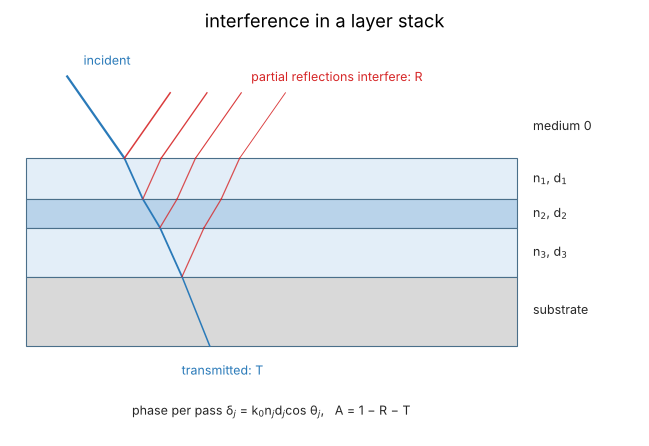

In [2]:
fig, ax = plt.subplots(figsize=(9, 5.2))
sketch.layer_stack(ax, title="interference in a layer stack")
plt.show()

## 1. Spectra of a stack

`tf.R_T_A_coeffs()` evaluates one wavelength and one angle at a time. The two
helpers below loop over wavelengths or angles. A layer's refractive index can be
a number or a function `n(wavelength)`, which is how dispersion enters later.
"Unpolarized" is the mean of s and p.

Wavelengths and thicknesses are in nm throughout.

In [3]:
def _eval(n, wavelength):
    return n(wavelength) if callable(n) else n


def RTA(wavelength, angle, layers, n_in=1.0, n_sub=1.52, pol="s"):
    # R, T, A for one wavelength and angle. layers: list of (n, kappa, d),
    # n and kappa may be callables of the wavelength.
    if pol == "unpolarized":
        return 0.5*(np.array(RTA(wavelength, angle, layers, n_in, n_sub, "s"))
                    + np.array(RTA(wavelength, angle, layers, n_in, n_sub, "p")))
    if len(layers) == 0:  # bare substrate: a layer of zero thickness
        layers = [(n_sub, 0.0, 0.0)]
    n = [_eval(l[0], wavelength) for l in layers]
    k = [_eval(l[1], wavelength) for l in layers]
    d = [l[2] for l in layers]
    return np.array(tf.R_T_A_coeffs(angle, n, k, d, _eval(n_in, wavelength), 0.0,
                                    _eval(n_sub, wavelength), 0.0, pol, wavelength))


def spectrum(wavelengths, angle, layers, **kwargs):
    # R, T, A as arrays over the wavelengths
    return np.array([RTA(wl, angle, layers, **kwargs) for wl in wavelengths]).T


def angle_scan(angles, wavelength, layers, **kwargs):
    # R, T, A as arrays over the angles of incidence
    return np.array([RTA(wavelength, a, layers, **kwargs) for a in angles]).T


def quarter_wave(n, wl_0):
    # physical thickness of a quarter wave layer at the design wavelength wl_0
    return wl_0/(4*n)

### Example: anti-reflection coating and Bragg mirror

A single MgF₂ layer ($n = 1.38$) of optical thickness $\lambda_0/4$ on glass
reduces the reflectance from 4.3 % to about 1.3 % at $\lambda_0 = 550$ nm. Eight
periods of alternating quarter wave layers TiO₂/SiO₂ ($n_H = 2.35$, $n_L = 1.46$)
form a Bragg mirror. Its stop band is centred at $\lambda_0$ on a frequency scale,
with half width $\frac{\Delta g}{g_0} = \frac{2}{\pi}\arcsin\frac{n_H - n_L}{n_H + n_L}$
in $g = 1/\lambda$; in wavelength it reaches from $\lambda_0/(1 + \Delta g/g_0)$ to
$\lambda_0/(1 - \Delta g/g_0)$. At oblique incidence the stop band moves to shorter
wavelengths (the phase thickness scales with $\cos\theta$ in each layer) and
becomes narrower for p than for s. The grey band is the stop band of an
infinite stack; with 8 periods R is close to 1 there and drops off more gently
at the edges. In the angle scan at 550 nm, the s band stays wide enough
to keep 550 nm inside at all angles, while the narrower and shifting p band
leaves it above about 55°. (The Brewster angle of the H/L interfaces cannot be
reached from air here: it would need $\sin\theta_0 = n_H n_L/\sqrt{n_H^2 + n_L^2} > 1$.)

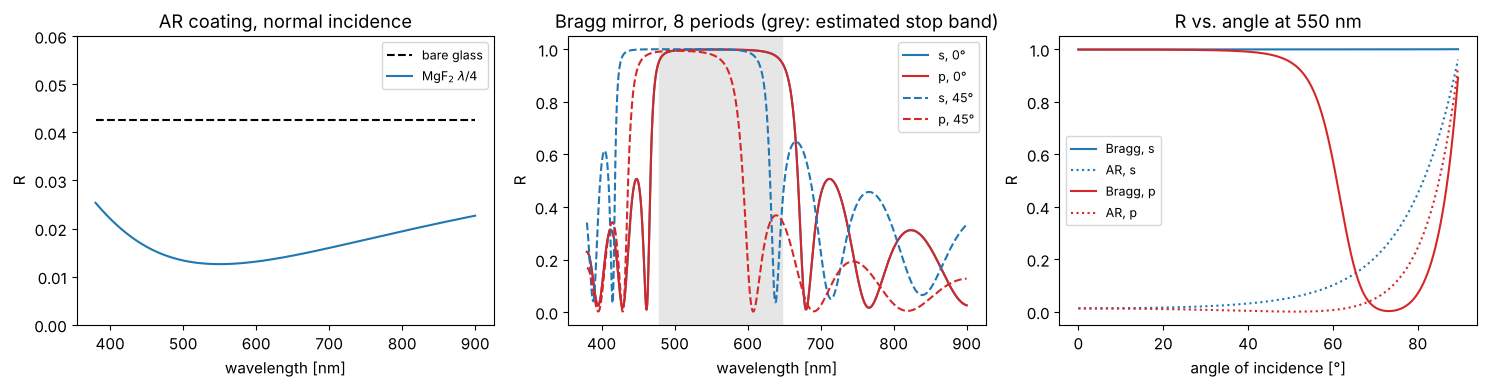

In [4]:
wl_0 = 550.0
nH, nL, n_glass = 2.35, 1.46, 1.52
ar = [(1.38, 0.0, quarter_wave(1.38, wl_0))]
bragg = [(nH, 0.0, quarter_wave(nH, wl_0)), (nL, 0.0, quarter_wave(nL, wl_0))]*8
wl = np.linspace(380, 900, 600)
theta = np.linspace(0, 89.5, 360)*deg

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(wl, spectrum(wl, 0, [], n_sub=n_glass)[0], "k--", label="bare glass")
axes[0].plot(wl, spectrum(wl, 0, ar, n_sub=n_glass)[0], label="MgF$_2$ $\\lambda/4$")
axes[0].set_ylim(0, 0.06); axes[0].set_ylabel("R")
axes[0].set_title("AR coating, normal incidence")
for a, ls in ((0, "-"), (45, "--")):
    for pol, c in (("s", "C0"), ("p", "C3")):
        axes[1].plot(wl, spectrum(wl, a*deg, bragg, n_sub=n_glass, pol=pol)[0],
                     color=c, ls=ls, label=f"{pol}, {a}°")
dg = 2/np.pi*np.arcsin((nH - nL)/(nH + nL))
axes[1].axvspan(wl_0/(1 + dg), wl_0/(1 - dg), color="0.9", zorder=0)
axes[1].set_ylabel("R"); axes[1].set_title("Bragg mirror, 8 periods (grey: estimated stop band)")
for pol, c in (("s", "C0"), ("p", "C3")):
    axes[2].plot(theta/deg, angle_scan(theta, wl_0, bragg, n_sub=n_glass, pol=pol)[0], color=c, label=f"Bragg, {pol}")
    axes[2].plot(theta/deg, angle_scan(theta, wl_0, ar, n_sub=n_glass, pol=pol)[0], color=c, ls=":", label=f"AR, {pol}")
axes[2].set_xlabel("angle of incidence [°]"); axes[2].set_ylabel("R")
axes[2].set_title(f"R vs. angle at {wl_0:.0f} nm")
for ax in axes[:2]:
    ax.set_xlabel("wavelength [nm]")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()

## 2. Interactive stack designer

The number of layers sets how many rows of $(n, \kappa, d)$ input fields are
shown; layer 1 is the one facing the incident light. Changing the layer count
keeps the values already entered and fills new layers with an alternating
quarter wave design at 550 nm. Presets load complete designs.

The left plot shows $R$, $T$ and $A$ versus wavelength at the chosen angle of
incidence; the right one shows them versus the angle of incidence at the chosen
wavelength (the dotted vertical line in the left plot). With
$\kappa > 0$, layers absorb, e.g. a thin metal film ($n \approx 0.06$,
$\kappa \approx 3.6$ for silver at 550 nm).

In [5]:
PRESETS = {
    "AR coating (MgF2)": [(1.38, 0.0, 99.6)],
    "quarter-quarter V coating": [(1.38, 0.0, 99.6), (1.70, 0.0, 80.9)],
    "Bragg mirror (5 periods)": [(2.35, 0.0, 58.5), (1.46, 0.0, 94.2)]*5,
    "Fabry-Perot filter": [(2.35, 0.0, 58.5), (1.46, 0.0, 94.2)]*3 + [(2.35, 0.0, 58.5), (1.46, 0.0, 188.4), (2.35, 0.0, 58.5)]
                          + [(1.46, 0.0, 94.2), (2.35, 0.0, 58.5)]*3,
    "silver film 40 nm": [(0.06, 3.6, 40.0)],
}
MAX_LAYERS = 16


def default_layer(i):
    n = 2.35 if i % 2 == 0 else 1.46
    return (n, 0.0, round(quarter_wave(n, 550.0), 1))


def plot_stack(layers, n_in, n_sub, pol, wl_range, angle_deg, wl_probe, N=500):
    wl = np.linspace(*wl_range, N)
    theta = np.linspace(0, 89.5, 360)*deg
    pols = ["s", "p"] if pol == "s and p" else [pol]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    for p, ls in zip(pols, ["-", "--"]):
        lbl = "" if len(pols) == 1 else f" ({p})"
        R, T, A = spectrum(wl, angle_deg*deg, layers, n_in=n_in, n_sub=n_sub, pol=p)
        Ra, Ta, Aa = angle_scan(theta, wl_probe, layers, n_in=n_in, n_sub=n_sub, pol=p)
        for ax, x, vals in ((axes[0], wl, (R, T, A)), (axes[1], theta/deg, (Ra, Ta, Aa))):
            for v, name, c in zip(vals, "RTA", ("C0", "C1", "C2")):
                if name == "A" and np.max(np.abs(v)) < 1e-6:
                    continue  # no absorption, skip
                ax.plot(x, v, color=c, ls=ls, label=name + lbl)
    axes[0].axvline(wl_probe, color="0.5", ls=":", lw=1)
    axes[0].set_xlabel("wavelength [nm]")
    axes[0].set_title(f"{pol}, angle of incidence {angle_deg:.1f}°")
    axes[1].set_xlabel("angle of incidence [°]")
    axes[1].set_title(f"{pol}, wavelength {wl_probe:.0f} nm")
    total = sum(l[2] for l in layers)
    fig.suptitle(f"{len(layers)} layers, total thickness {total:.0f} nm, "
                 f"$n_\\mathrm{{in}}$ = {n_in}, $n_\\mathrm{{sub}}$ = {n_sub}", y=1.0)
    for ax in axes:
        ax.set_ylim(-0.02, 1.02); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="best")
    fig.tight_layout()
    plt.show()

In [6]:
class StackDesigner:
    def __init__(self, layers):
        style = {"description_width": "initial"}
        lay = widgets.Layout(width="150px")
        self.rows = [(widgets.BoundedFloatText(value=1.5, min=0.01, max=10, step=0.01, description=f"n{i+1}", layout=lay),
                      widgets.BoundedFloatText(value=0.0, min=0, max=20, step=0.01, description=f"κ{i+1}", layout=lay),
                      widgets.BoundedFloatText(value=100., min=0, max=1e5, step=1, description=f"d{i+1} [nm]", layout=lay, style=style))
                     for i in range(MAX_LAYERS)]
        self.n_layers = widgets.IntSlider(value=len(layers), min=0, max=MAX_LAYERS, description="layers")
        self.preset = widgets.Dropdown(options=["(custom)"] + list(PRESETS), description="preset")
        self.n_in = widgets.BoundedFloatText(value=1.0, min=0.1, max=5, step=0.01, description="n embedding", style=style, layout=widgets.Layout(width="180px"))
        self.n_sub = widgets.BoundedFloatText(value=1.52, min=0.1, max=5, step=0.01, description="n substrate", style=style, layout=widgets.Layout(width="180px"))
        self.pol = widgets.ToggleButtons(options=["s", "p", "s and p", "unpolarized"], value="s and p", description="polarization")
        self.wl_range = widgets.FloatRangeSlider(value=(380, 900), min=200, max=2000, step=10, description="λ range [nm]", style=style, continuous_update=False, layout=widgets.Layout(width="450px"))
        self.angle = widgets.FloatSlider(value=0, min=0, max=89, step=0.5, description="angle [°]", continuous_update=False)
        self.wl_probe = widgets.FloatSlider(value=550, min=200, max=2000, step=5, description="λ for angle scan [nm]", style=style, continuous_update=False, layout=widgets.Layout(width="450px"))
        self.layer_box = widgets.VBox()
        self.out = widgets.Output()
        self._busy = False
        self.set_layers(layers)
        self.n_layers.observe(self._on_count, "value")
        self.preset.observe(self._on_preset, "value")
        for w in [self.n_in, self.n_sub, self.pol, self.wl_range, self.angle, self.wl_probe] + [w for r in self.rows for w in r]:
            w.observe(self._on_change, "value")
        self._show_rows()
        self.update()

    def layers(self):
        return [tuple(w.value for w in row) for row in self.rows[:self.n_layers.value]]

    def set_layers(self, layers):
        self._busy = True
        for row, vals in zip(self.rows, layers):
            for w, v in zip(row, vals):
                w.value = v
        self.n_layers.value = len(layers)
        self._busy = False

    def _show_rows(self):
        self.layer_box.children = [widgets.HBox(r) for r in self.rows[:self.n_layers.value]]

    def _on_count(self, change):
        if not self._busy:
            self._busy = True
            for i in range(change["old"], change["new"]):  # fill newly added layers
                for w, v in zip(self.rows[i], default_layer(i)):
                    w.value = v
            self.preset.value = "(custom)"
            self._busy = False
        self._show_rows()
        self.update()

    def _on_preset(self, change):
        if change["new"] in PRESETS:
            self.set_layers(PRESETS[change["new"]])
            self._show_rows()
            self.update()

    def _on_change(self, change):
        if not self._busy:
            self.update()

    def update(self):
        self.out.clear_output(wait=True)
        with self.out:
            plot_stack(self.layers(), self.n_in.value, self.n_sub.value, self.pol.value,
                       self.wl_range.value, self.angle.value, self.wl_probe.value)

    def widget(self):
        controls = widgets.VBox([widgets.HBox([self.preset, self.n_layers]),
                                 widgets.HBox([self.n_in, self.n_sub]), self.pol,
                                 widgets.HBox([self.wl_range, self.angle]), self.wl_probe])
        return widgets.VBox([widgets.HBox([controls, self.layer_box]), self.out])


designer = StackDesigner(PRESETS["Fabry-Perot filter"])
display(designer.widget())

**Static view of the default setting** (Fabry-Perot filter: two quarter wave
mirrors around a half wave SiO₂ spacer, s and p, normal incidence). The narrow
transmission peak at 550 nm sits in the middle of the mirrors' stop band. In the
angle scan at 550 nm, the peak tunes away from the probe wavelength: above about
10° the filter blocks 550 nm, and p tolerates tilt slightly better than s.

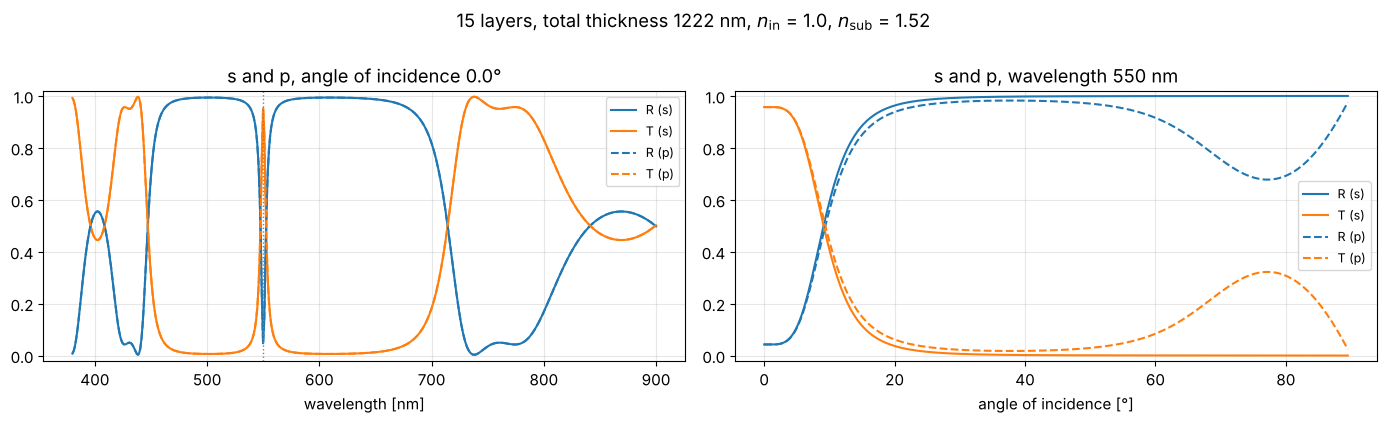

In [7]:
plot_stack(PRESETS["Fabry-Perot filter"], 1.0, 1.52, "s and p", (380, 900), 0.0, 550.0)

The same function, at 30° for a 40 nm silver film: even a 40 nm film
reflects more than 90 %, transmits a few percent (more in the red) and absorbs
about 2 %. Unlike for dielectric layers, the absorptance $A$ is not zero.

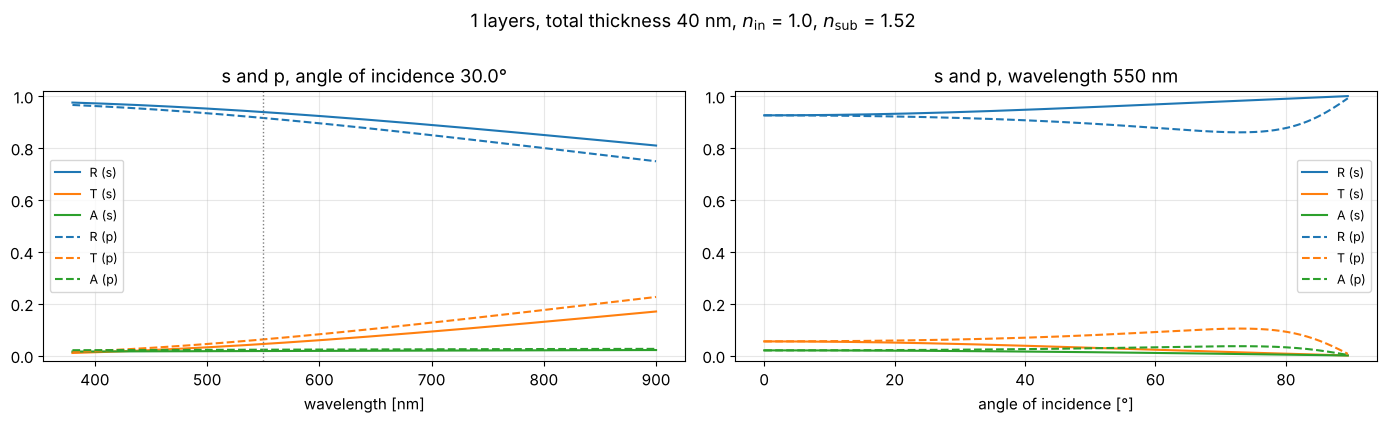

In [8]:
plot_stack(PRESETS["silver film 40 nm"], 1.0, 1.52, "s and p", (380, 900), 30.0, 550.0)

(The constant $n$, $\kappa$ used for silver are a rough value at 550 nm; real
metals are strongly dispersive. Enter tabulated data via callables, as shown for
glasses in the next section.)

## 3. Dispersion with the Abbe model

A glass catalogue characterizes a glass by its refractive index $n_d$ at the helium
d line ($\lambda_d = 587.6$ nm) and its **Abbe number**

$$V_d = \frac{n_d - 1}{n_F - n_C}$$

with the hydrogen lines F (486.1 nm) and C (656.3 nm). Small $V_d$ means strong
dispersion (flint glasses), large $V_d$ weak dispersion (crown glasses).
`pyoptics.materials.abbe_dispersion()` turns $(n_d, V_d)$ into a dispersion curve
with the two-term Cauchy formula

$$n(\lambda) = A + \frac{B}{\lambda^2}, \qquad
B = \frac{n_d - 1}{V_d}\left(\frac{1}{\lambda_F^2} - \frac{1}{\lambda_C^2}\right)^{-1}, \qquad
A = n_d - \frac{B}{\lambda_d^2},$$

which reproduces $n_d$ and $V_d$ exactly. For N-BK7 it agrees with Schott's
Sellmeier formula to a few $10^{-4}$ in the visible, but it misses the
absorption bands, so it gets worse in the UV and IR.

N-BK7 model: n_d = 1.5168, V_d = 64.17


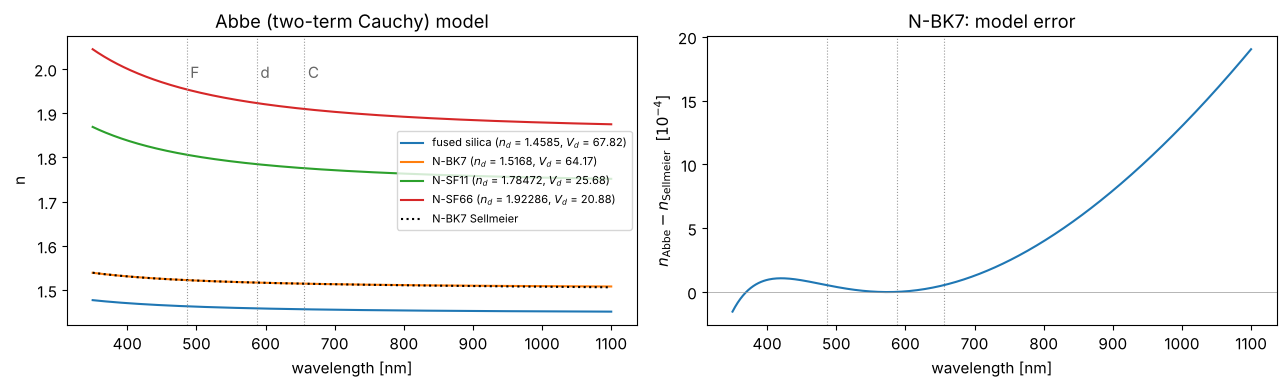

In [9]:
glasses = {"fused silica": (1.4585, 67.82), "N-BK7": (1.5168, 64.17),
           "N-SF11": (1.78472, 25.68), "N-SF66": (1.92286, 20.88)}

def n_bk7_sellmeier(wl_nm):
    B = (1.03961212, 0.231792344, 1.01046945)
    C = (0.00600069867, 0.0200179144, 103.560653)
    wl2 = (wl_nm/1000)**2
    return np.sqrt(1 + sum(b*wl2/(wl2 - c) for b, c in zip(B, C)))

wl = np.linspace(350, 1100, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, (n_d, V_d) in glasses.items():
    axes[0].plot(wl, mat.abbe_dispersion(wl, n_d, V_d), label=f"{name} ($n_d$ = {n_d}, $V_d$ = {V_d})")
axes[0].plot(wl, n_bk7_sellmeier(wl), "k:", label="N-BK7 Sellmeier")
for line, lw in ((mat.LAMBDA_F, "F"), (mat.LAMBDA_d, "d"), (mat.LAMBDA_C, "C")):
    for ax in axes:
        ax.axvline(line, color="0.6", lw=0.8, ls=":")
    axes[0].text(line + 5, 1.98, lw, color="0.4")
axes[0].set_ylabel("n"); axes[0].set_title("Abbe (two-term Cauchy) model")
axes[0].legend(fontsize=8, loc="center right")
dn = mat.abbe_dispersion(wl, 1.5168, 64.17) - n_bk7_sellmeier(wl)
axes[1].plot(wl, dn*1e4)
axes[1].axhline(0, color="0.6", lw=0.5)
axes[1].set_ylabel("$n_\\mathrm{Abbe} - n_\\mathrm{Sellmeier}$  [$10^{-4}$]")
axes[1].set_title("N-BK7: model error")
for ax in axes:
    ax.set_xlabel("wavelength [nm]")
fig.tight_layout()

n_d, n_F, n_C = mat.abbe_dispersion([mat.LAMBDA_d, mat.LAMBDA_F, mat.LAMBDA_C], 1.5168, 64.17)
print(f"N-BK7 model: n_d = {n_d:.4f}, V_d = {mat.abbe_number(n_d, n_F, n_C):.2f}")

### Dispersive layers in a stack

Dispersion enters the stack by passing functions `n(wavelength)` instead of
numbers. Two examples:

- **Bragg mirror** from a dense flint (N-SF66, high index) and fused silica (low
  index), both quarter wave at $\lambda_0$ = 1200 nm. A quarter wave stack has a
  further stop band at $\lambda_0/3$ = 400 nm. With constant indices (frozen at
  $\lambda_0$) it sits exactly there; with dispersion both indices are larger in
  the blue, the optical thicknesses grow, and the band moves to longer
  wavelengths and widens, since the index contrast grows as well. Near
  $\lambda_0$ the two models agree. (Beyond 1 µm the two-term model is only
  rough, see above, but it serves for illustration.)
- **AR coating on a flint substrate:** the reflectance of bare N-SF11 rises
  towards the blue simply because $n$ does; a MgF₂ quarter wave layer cannot
  compensate that equally at all wavelengths. With the coating the effect is
  smaller, the dispersive substrate mostly raises R in the blue.

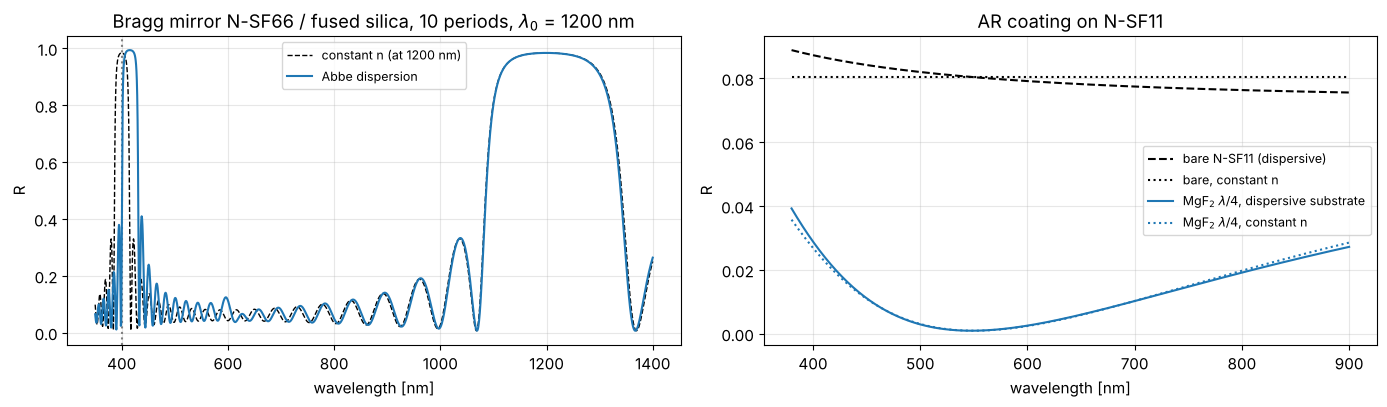

In [10]:
wl_0 = 1200.0
n_H = lambda wl: mat.abbe_dispersion(wl, *glasses["N-SF66"])
n_L = lambda wl: mat.abbe_dispersion(wl, *glasses["fused silica"])
d_H, d_L = quarter_wave(n_H(wl_0), wl_0), quarter_wave(n_L(wl_0), wl_0)
mirror_disp = [(n_H, 0.0, d_H), (n_L, 0.0, d_L)]*10
mirror_const = [(n_H(wl_0), 0.0, d_H), (n_L(wl_0), 0.0, d_L)]*10
n_sub_bk7 = lambda wl: mat.abbe_dispersion(wl, *glasses["N-BK7"])

wl = np.linspace(350, 1400, 1500)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(wl, spectrum(wl, 0, mirror_const, n_sub=n_sub_bk7)[0], "k--", lw=1, label=f"constant n (at {wl_0:.0f} nm)")
axes[0].axvline(wl_0/3, color="0.5", ls=":")
axes[0].plot(wl, spectrum(wl, 0, mirror_disp, n_sub=n_sub_bk7)[0], label="Abbe dispersion")
axes[0].set_title(f"Bragg mirror N-SF66 / fused silica, 10 periods, $\\lambda_0$ = {wl_0:.0f} nm")
axes[0].set_ylabel("R")

n_sf11 = lambda wl: mat.abbe_dispersion(wl, *glasses["N-SF11"])
wl_0 = 550.0
wl = np.linspace(380, 900, 400)
n_mgf2 = 1.38
ar = [(n_mgf2, 0.0, quarter_wave(n_mgf2, wl_0))]
axes[1].plot(wl, spectrum(wl, 0, [], n_sub=n_sf11)[0], "k--", label="bare N-SF11 (dispersive)")
axes[1].plot(wl, spectrum(wl, 0, [], n_sub=n_sf11(wl_0))[0], "k:", label="bare, constant n")
axes[1].plot(wl, spectrum(wl, 0, ar, n_sub=n_sf11)[0], label="MgF$_2$ $\\lambda/4$, dispersive substrate")
axes[1].plot(wl, spectrum(wl, 0, ar, n_sub=n_sf11(wl_0))[0], ":", color="C0", label="MgF$_2$ $\\lambda/4$, constant n")
axes[1].set_title("AR coating on N-SF11"); axes[1].set_ylabel("R")
for ax in axes:
    ax.set_xlabel("wavelength [nm]"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout()

### Interactive: Bragg mirror from two Abbe glasses

Choose $n_d$ and $V_d$ for the high and low index material, the number of
periods and the design wavelength $\lambda_0$ (both layers are quarter wave at
$\lambda_0$). The upper plot compares the reflectance with the dispersion free
case (indices frozen at $\lambda_0$), the lower one shows both $n(\lambda)$ curves.
Setting $V_d$ to its maximum (1000) practically switches dispersion off.

In [11]:
def plot_abbe_mirror(nd_H, Vd_H, nd_L, Vd_L, periods, wl_0, angle_deg, pol, wl_range):
    nH = lambda wl: mat.abbe_dispersion(wl, nd_H, Vd_H)
    nL = lambda wl: mat.abbe_dispersion(wl, nd_L, Vd_L)
    dH, dL = quarter_wave(nH(wl_0), wl_0), quarter_wave(nL(wl_0), wl_0)
    disp = [(nH, 0.0, dH), (nL, 0.0, dL)]*periods
    const = [(nH(wl_0), 0.0, dH), (nL(wl_0), 0.0, dL)]*periods
    wl = np.linspace(*wl_range, 800)
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    axes[0].plot(wl, spectrum(wl, angle_deg*deg, const, n_sub=1.52, pol=pol)[0], "k--", lw=1, label="constant n")
    axes[0].plot(wl, spectrum(wl, angle_deg*deg, disp, n_sub=1.52, pol=pol)[0], label="Abbe dispersion")
    axes[0].set_ylabel("R"); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)
    axes[0].set_title(f"{periods} periods, quarter wave at {wl_0:.0f} nm, {pol}, {angle_deg:.1f}°, substrate n = 1.52")
    axes[1].plot(wl, nH(wl), color="C3", label=f"H: $n_d$ = {nd_H:.3f}, $V_d$ = {Vd_H:.1f}")
    axes[1].plot(wl, nL(wl), color="C0", label=f"L: $n_d$ = {nd_L:.3f}, $V_d$ = {Vd_L:.1f}")
    axes[1].axvline(wl_0, color="0.5", ls=":")
    axes[0].axvline(wl_0/3, color="0.5", ls=":")
    axes[1].set_ylabel("n"); axes[1].set_xlabel("wavelength [nm]"); axes[1].legend(fontsize=9)
    fig.tight_layout()
    plt.show()

s = {"continuous_update": False, "style": {"description_width": "initial"}}
abbe_controls = dict(
    nd_H=widgets.FloatSlider(value=1.92286, min=1.3, max=2.5, step=0.005, description="H: n_d", readout_format=".3f", **s),
    Vd_H=widgets.FloatSlider(value=20.88, min=10, max=1000, step=0.5, description="H: V_d", **s),
    nd_L=widgets.FloatSlider(value=1.4585, min=1.3, max=2.5, step=0.005, description="L: n_d", readout_format=".3f", **s),
    Vd_L=widgets.FloatSlider(value=67.82, min=10, max=1000, step=0.5, description="L: V_d", **s),
    periods=widgets.IntSlider(value=10, min=1, max=30, description="periods", **s),
    wl_0=widgets.FloatSlider(value=1200, min=300, max=2000, step=5, description="λ0 [nm]", **s),
    angle_deg=widgets.FloatSlider(value=0, min=0, max=89, step=0.5, description="angle [°]", **s),
    pol=widgets.ToggleButtons(options=["s", "p", "unpolarized"], value="s", description="polarization"),
    wl_range=widgets.FloatRangeSlider(value=(350, 1400), min=200, max=2500, step=10, description="λ range [nm]", **s),
)
c = abbe_controls
display(widgets.VBox([
    widgets.HBox([widgets.VBox([c["nd_H"], c["Vd_H"], c["periods"], c["angle_deg"]]),
                  widgets.VBox([c["nd_L"], c["Vd_L"], c["wl_0"], c["wl_range"]])]),
    c["pol"],
    widgets.interactive_output(plot_abbe_mirror, abbe_controls),
]))

**Static view of the default setting** (N-SF66 / fused silica, 10 periods,
$\lambda_0$ = 1200 nm, normal incidence; dotted line: $\lambda_0/3$):

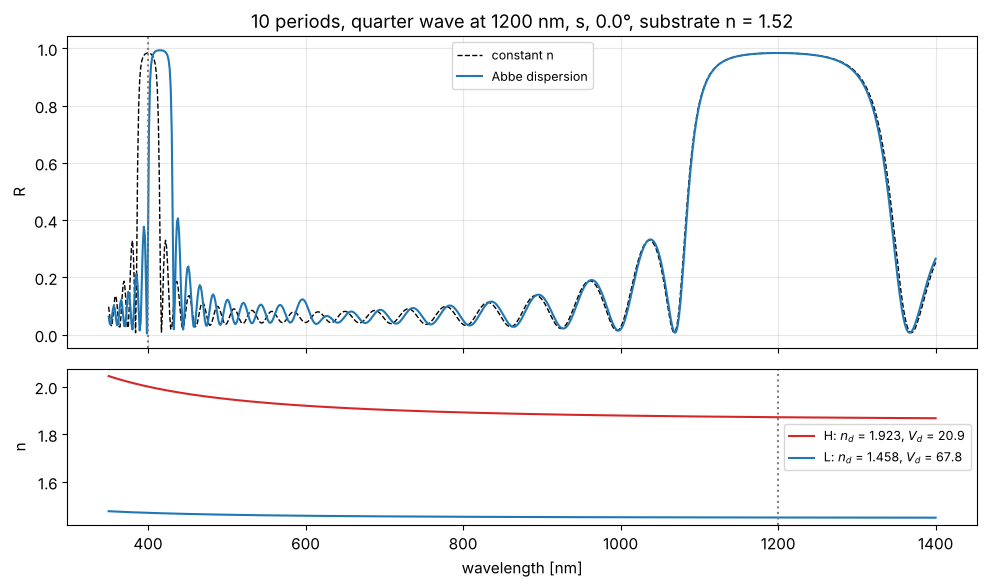

In [12]:
plot_abbe_mirror(1.92286, 20.88, 1.4585, 67.82, 10, 1200.0, 0.0, "s", (350, 1400))

Things to try: raise $V_d$ of the high index material to 1000 and the
dispersive and constant curves coincide; lower it to 10 and the third order
stop band near $\lambda_0/3$ moves markedly. Tilting the stack moves all stop bands to
shorter wavelengths, for p polarization they also become narrower.

## 4. Thick substrates: a coated lens in a spectrophotometer

A lens or a window is a few millimetres thick, a layer stack like any other:
coating, glass, coating, in air. Computed coherently, the glass is a
Fabry-Pérot etalon whose fringes are spaced by
$\Delta\lambda = \lambda^2/(2 n d\cos\theta)$, only 0.02 nm for 5 mm of N-BK7 at
550 nm. A spectrophotometer with a slit width of 1 nm averages over dozens of
them: the multiple reflections in the glass add up in **intensity**, while the
light in the thin coatings still interferes.

`R_T_A_coeffs(..., incoherent=[False, True, False])` flags the glass as such a
thick layer. The substrate of the stack is then the air behind the lens. The
default is the exact incoherent sum (Katsidis and Papadopoulos): each
coating is a coherent sub-stack with power reflectances and transmittances
for light from either side, the glass passes the fraction $\tau$ in a single
pass, and the reflections between the coatings form a geometric series,

$$T = \frac{T_1\,\tau\,T_2}{1 - R_1' R_2 \tau^2},$$

with $R_1'$ the reflectance of the front coating seen from inside the glass.
For an AR coated lens $R_1' R_2 \approx 10^{-4}$: the transmission is the
product of the two coatings' transmittances and the internal transmission,
and the denominator only matters for uncoated or mirror coated plates.

Below: N-BK7 with a weak absorption ($\kappa = 2\cdot 10^{-8}$, about 0.2 %
loss in 5 mm at 550 nm) and a MgF₂ quarter wave layer at 550 nm on both
sides. Computed coherently on a 0.5 nm grid, the spectrum is noise: the grid
samples the fringes at random phases. The incoherent result is smooth.

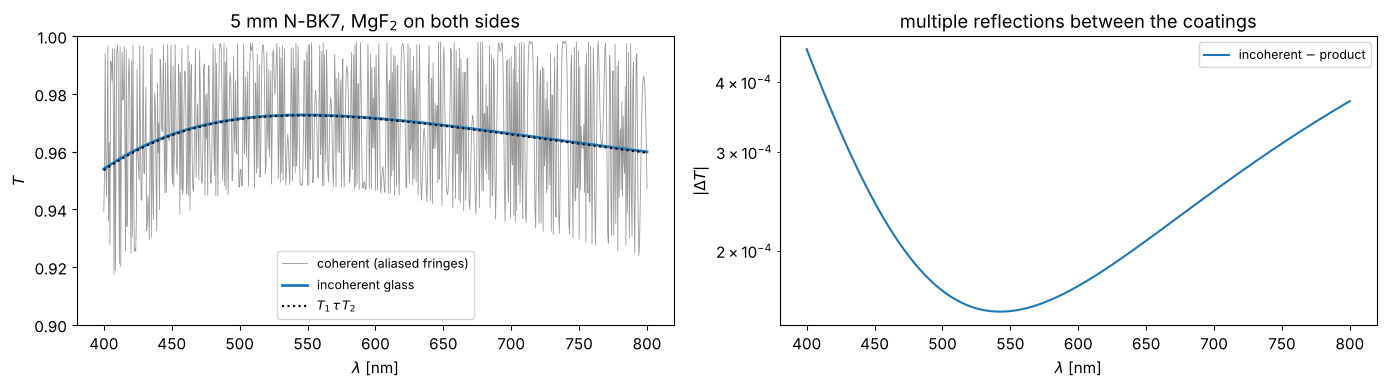

In [13]:
wl_lens = np.linspace(400, 800, 801)
d_glass, kappa_glass = 5e6, 2e-8  # 5 mm in nm
d_mgf2 = quarter_wave(1.38, 550.0)


def coated_lens(wavelength, angle=0.0, pol="s", **kw):
    n_g = n_bk7_sellmeier(wavelength)
    return np.array(tf.R_T_A_coeffs(angle, [1.38, n_g, 1.38], [0.0, kappa_glass, 0.0],
                                    [d_mgf2, d_glass, d_mgf2], 1.0, 0.0, 1.0, 0.0, pol, wavelength, **kw))


T_coh = np.array([coated_lens(l)[1] for l in wl_lens])
T_inc = np.array([coated_lens(l, incoherent=[False, True, False])[1] for l in wl_lens])
# product of the single surfaces and the internal transmission:
T_1 = np.array([tf.R_T_A_coeffs(0.0, [1.38], [0.0], [d_mgf2], 1.0, 0.0, n_bk7_sellmeier(l), kappa_glass,
                                "s", l)[1] for l in wl_lens])
tau = np.exp(-4*np.pi*kappa_glass*d_glass/wl_lens)
T_prod = T_1**2*tau

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(wl_lens, T_coh, lw=0.6, color="0.6", label="coherent (aliased fringes)")
axes[0].plot(wl_lens, T_inc, lw=2, label="incoherent glass")
axes[0].plot(wl_lens, T_prod, "k:", label=r"$T_1\,\tau\,T_2$")
axes[0].set_xlabel(r"$\lambda$ [nm]"); axes[0].set_ylabel("$T$"); axes[0].set_ylim(0.9, 1.0)
axes[0].legend(fontsize=9); axes[0].set_title("5 mm N-BK7, MgF$_2$ on both sides")
axes[1].semilogy(wl_lens, np.abs(T_inc - T_prod), label="incoherent $-$ product")
axes[1].set_xlabel(r"$\lambda$ [nm]"); axes[1].set_ylabel(r"$|\Delta T|$")
axes[1].set_title("multiple reflections between the coatings"); axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

The difference between the full incoherent result and the simple product is
the light reflected back and forth between the two coatings, a few
$10^{-4}$, largest where the single layer AR coating is worst.

### Partial coherence: how wide is wide enough?

Whether a thick layer is coherent depends on the light, not only on the layer.
`bandwidth` sets the full width at half maximum of a Gaussian spectrum around
`wavelength`. The phase $k_0 n d\cos\theta$ of each flagged layer spreads with
the wavenumbers of the spectrum, and $R$, $T$ are averaged over it; the
coatings are evaluated at the centre wavelength. The fringes fade once the
bandwidth exceeds the fringe spacing: a laser line ($\ll$ 1 pm) sees the
etalon, a spectrophotometer does not. The coherence length
$l_c \approx \lambda^2/\Delta\lambda$ compared with the round trip $2nd$ says
the same.

To make the fringes visible, the plot uses an uncoated 5 mm plate (an AR coated
one has fringes 100 times weaker) and a 0.1 nm window.

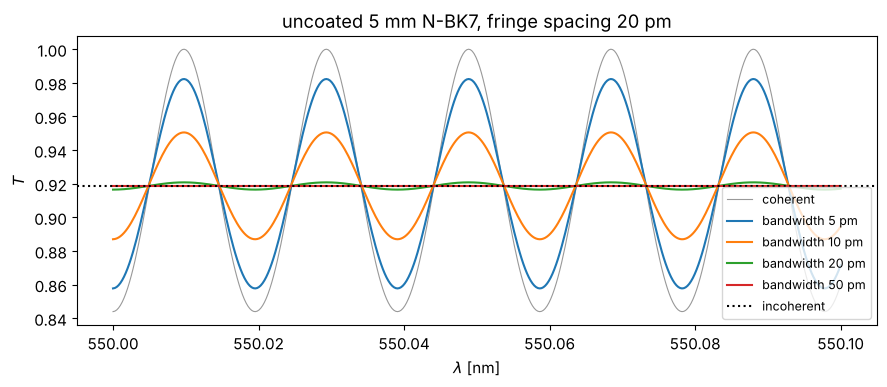

In [14]:
def bare_plate(wavelength, **kw):
    n_g = n_bk7_sellmeier(wavelength)
    return np.array(tf.R_T_A_coeffs(0.0, [n_g], [0.0], [d_glass], 1.0, 0.0, 1.0, 0.0, "s", wavelength, **kw))


wl_zoom = np.linspace(550.0, 550.1, 400)
fringe = 550.0**2/(2*n_bk7_sellmeier(550.0)*d_glass)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(wl_zoom, [bare_plate(l)[1] for l in wl_zoom], color="0.6", lw=0.8, label="coherent")
for bw in (0.005, 0.01, 0.02, 0.05):
    ax.plot(wl_zoom, [bare_plate(l, incoherent=[True], bandwidth=bw)[1] for l in wl_zoom],
            label=f"bandwidth {1000*bw:.0f} pm")
ax.axhline(bare_plate(550.0, incoherent=[True])[1], color="k", ls=":", label="incoherent")
ax.set_xlabel(r"$\lambda$ [nm]"); ax.set_ylabel("$T$")
ax.set_title(f"uncoated 5 mm N-BK7, fringe spacing {1000*fringe:.0f} pm")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

For several thick layers the phase spreads are not independent: they all come
from the same spread of wavenumbers. Two equal plates keep interfering through
paths of equal length (one round trip in either plate) however broad the
spectrum, which the fully incoherent sum misses and the `bandwidth` average
keeps.

### Oblique incidence and curved surfaces

The plane stack describes a collimated beam through a nearly flat element. On
a strongly curved lens the angle of incidence varies over the aperture (and
the coatings get thinner towards the rim); the transmission at each point is
that of the stack at the local angle, s and p separately, averaged for
unpolarized light:

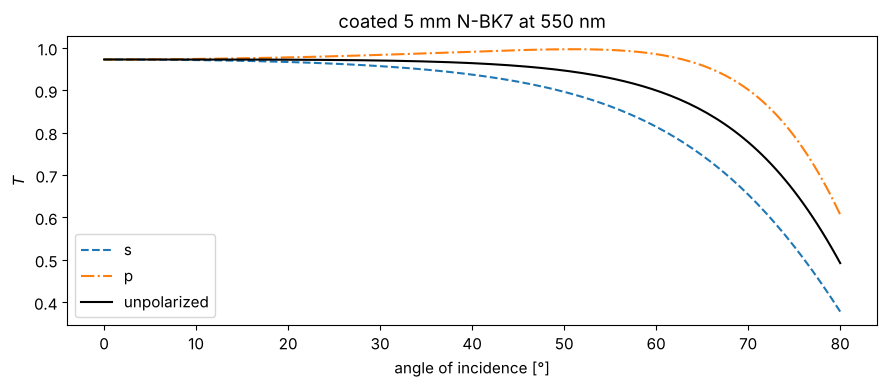

In [15]:
theta = np.linspace(0, 80, 161)*deg
fig, ax = plt.subplots(figsize=(9, 4))
for pol, ls in (("s", "--"), ("p", "-.")):
    ax.plot(theta/deg, [coated_lens(550.0, a, pol, incoherent=[False, True, False])[1] for a in theta],
            ls, label=pol)
ax.plot(theta/deg, [0.5*(coated_lens(550.0, a, "s", incoherent=[False, True, False])[1]
                         + coated_lens(550.0, a, "p", incoherent=[False, True, False])[1]) for a in theta],
        "k", label="unpolarized")
ax.set_xlabel(r"angle of incidence [°]"); ax.set_ylabel("$T$"); ax.legend()
ax.set_title(r"coated 5 mm N-BK7 at 550 nm")
fig.tight_layout()
plt.show()

In a real lens the two surfaces see different local angles, and a light ray
reflected twice inside leaves along another path: it becomes a ghost image,
not part of the transmitted beam. For a curved lens the transmission is
therefore traced ray by ray, with a `coatings.Coating` on each surface and the
absorption of the glass along the path, as in notebook
[20 (polarization ray tracing)](20_polarization_raytrace.ipynb); where the
twice reflected light goes is the subject of notebook
[92 (flare and ghosts)](92_flare_ghosts.ipynb).

## Summary

- `thin_films.R_T_A_coeffs()` gives $R$, $T$ and $A$ of any stack; the two helpers scan wavelength and angle, unpolarized as the mean of s and p.
- Quarter wave designs: an anti-reflection layer, Bragg mirrors whose stop band is set by the index contrast, and a Fabry-Perot filter. All of them move to shorter wavelengths when tilted, and p behaves differently from s.
- A lens or window is a thick layer between two coatings: flagged with `incoherent`, its multiple reflections add up in intensity, and `bandwidth` covers the partially coherent case in between (fringes fade once the bandwidth exceeds $\lambda^2/(2nd)$). For AR coatings the transmission is essentially $T_1\,\tau\,T_2$.
- Metal layers absorb: a 40 nm silver film reflects more than 90 % and absorbs a few percent.
- The Abbe model $(n_d, V_d)$ gives a dispersion curve good to a few $10^{-4}$ in the visible; dispersion moves and widens the higher order stop bands.
- Two Bragg mirrors around a half wave spacer make a narrow band interference filter; its bandwidth, angle shift and the linear variable filter are in notebook [113 (Fabry–Perot and filters)](113_fabry_perot_filters.ipynb).

## References

- H. A. Macleod, *Thin-Film Optical Filters*, 3rd ed., Institute of Physics Publishing (2001).
- P. Yeh, *Optical Waves in Layered Media*, Wiley (1988).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008).